In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
data = pd.read_csv("WineQT.csv")
data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [4]:
data.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')

In [6]:
# EDA IMPLEMENTATION
data.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

EDA PART 

In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 107.3 KB


In [8]:
data.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000
mean,8.311111,0.531339,0.268364,2.532152,0.086933,15.615486,45.914698,0.996730,3.311015,0.657708,10.442111,5.657043
std,1.747595,0.179633,0.196686,1.355917,0.047267,10.250486,32.782130,0.001925,0.156664,0.170399,1.082196,0.805824
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.392500,0.090000,1.900000,0.070000,7.000000,21.000000,0.995570,3.205000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,37.000000,0.996680,3.310000,0.620000,10.200000,6.000000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,61.000000,0.997845,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


CHECK DUPLICATE ROWS

In [9]:
duplicate_count = data.duplicated().sum()
print(f"Duplicate rows: {duplicate_count}")

Duplicate rows: 125


In [10]:
# 1. Remove duplicate rows and reset the row index
data = data.drop_duplicates().reset_index(drop=True)

# 2. Verify duplicates are removed and check the new shape
print(f"Remaining duplicates: {data.duplicated().sum()}")
print(f"New shape: {data.shape}")

Remaining duplicates: 0
New shape: (1018, 12)


# Missing Values

In [11]:
# Check count and percentage of missing values per column
missing = data.isnull().sum()
missing_pct = (data.isnull().sum() / len(data)) * 100
missing_df = pd.DataFrame({"Missing Count": missing, "Percentage (%)": missing_pct})
print(missing_df[missing_df["Missing Count"] > 0])

Empty DataFrame
Columns: [Missing Count, Percentage (%)]
Index: []


#  Drop the Irrelevant Id Column

In [12]:
# Drop 'Id' column if present
if 'Id' in data.columns:
    data = data.drop(columns=['Id'])
    print("Dropped 'Id' column successfully!")

# Analyze Your Target Variable (quality)

quality
3      6
4     33
5    433
6    409
7    122
8     15
Name: count, dtype: int64


C:\Users\ABHINANDAN NAIK\AppData\Local\Temp\ipykernel_4484\1727265440.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data, x='quality', palette='Set2')


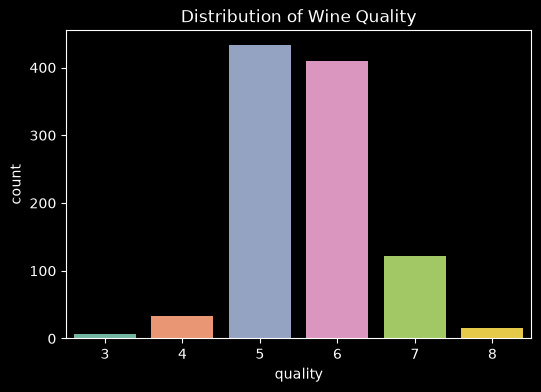

In [13]:
# 1. Check value counts of wine quality
print(data['quality'].value_counts().sort_index())

# 2. Visualize target distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=data, x='quality', palette='Set2')
plt.title("Distribution of Wine Quality")
plt.show()

# Correlation Heatmap (Feature Importance)

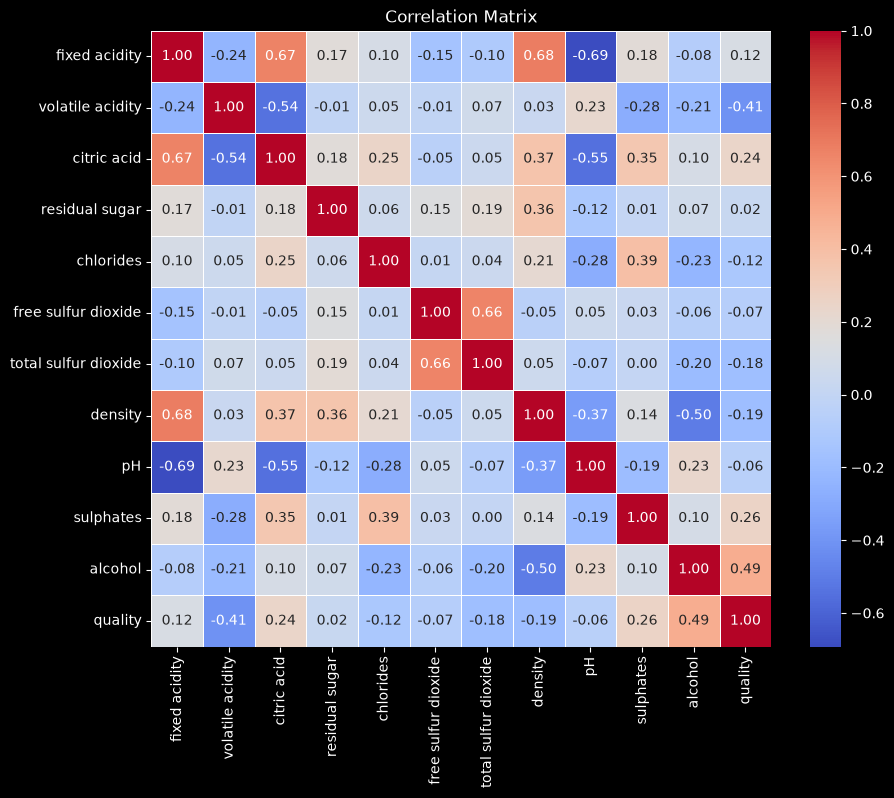

In [14]:
plt.figure(figsize=(10, 8))
sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Matrix")
plt.show()

# Check Outliers Via Box Plot

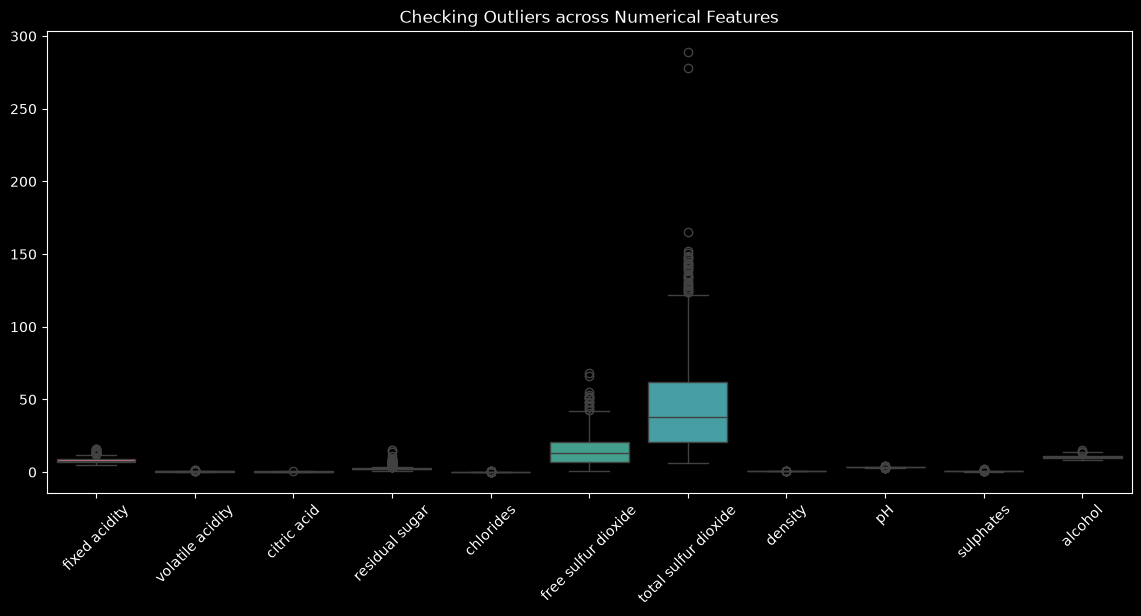

In [15]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=data.drop(columns=['quality']))
plt.xticks(rotation=45)
plt.title("Checking Outliers across Numerical Features")
plt.show()

# Feature Scaling (⚠️ Mandatory for SVM)

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate features (X) and target (y)
X = data.drop('quality', axis=1)
y = data['quality']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# IQR Capping

In [17]:
# List of features with significant outliers
outlier_features = ['residual sugar', 'chlorides', 'sulphates', 'total sulfur dioxide', 'fixed acidity']

for col in outlier_features:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Cap values: values below lower_bound become lower_bound, values above become upper_bound
    data[col] = data[col].clip(lower=lower_bound, upper=upper_bound)

print("Outliers capped successfully! No rows were deleted.")

Outliers capped successfully! No rows were deleted.


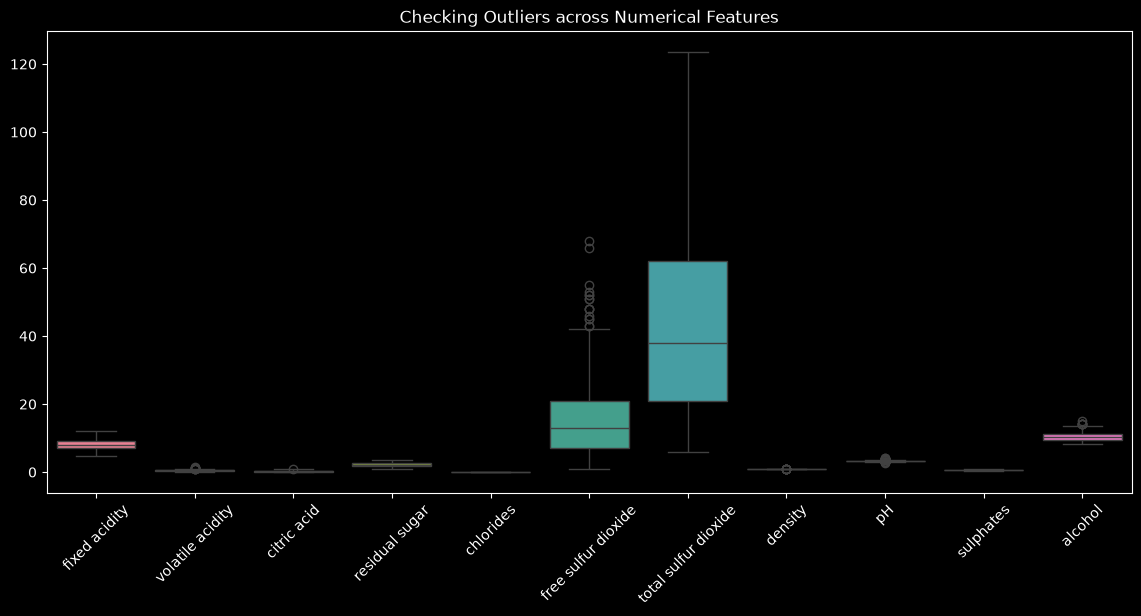

In [18]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=data.drop(columns=['quality']))
plt.xticks(rotation=45)
plt.title("Checking Outliers across Numerical Features")
plt.show()

# Re-split & Re-scale (Using your Capped Data)

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Separate features (X) and target (y)
X = data.drop('quality', axis=1)
y = data['quality']

# 2. Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Standardize features (essential for SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data successfully split and scaled!")
print(f"Train samples: {X_train_scaled.shape[0]}, Test samples: {X_test_scaled.shape[0]}")

Data successfully split and scaled!
Train samples: 814, Test samples: 204


# Train the Support Vector Classifier (SVC)

In [20]:
from sklearn.svm import SVC

# Initialize Support Vector Classifier (RBF kernel by default)
svm_model = SVC(kernel='rbf', C=1.0, random_state=42)

# Train the model
svm_model.fit(X_train_scaled, y_train)

print("SVM Model trained successfully!")

SVM Model trained successfully!


# Make Predictions & Evaluate

Accuracy: 58.33%

Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         7
           5       0.63      0.70      0.66        87
           6       0.53      0.60      0.56        82
           7       0.60      0.38      0.46        24
           8       0.00      0.00      0.00         3

    accuracy                           0.58       204
   macro avg       0.29      0.28      0.28       204
weighted avg       0.55      0.58      0.56       204



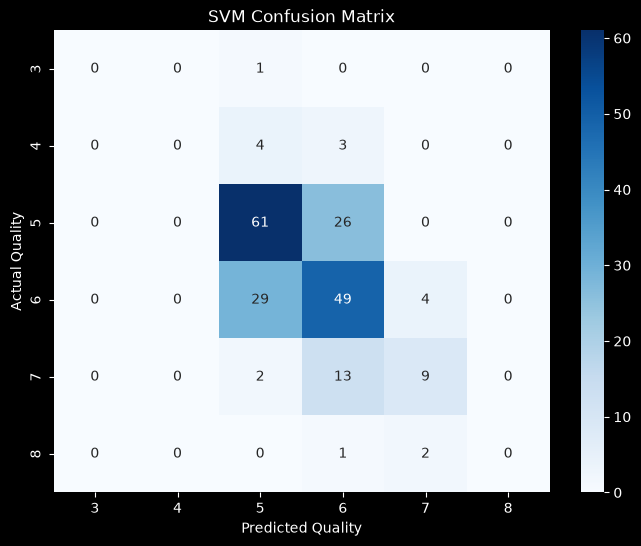

In [21]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Predict on test data
y_pred = svm_model.predict(X_test_scaled)

# 1. Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%\n")

# 2. Classification Report (Precision, Recall, F1-Score per wine rating)
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# 3. Confusion Matrix Visualization
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.xlabel("Predicted Quality")
plt.ylabel("Actual Quality")
plt.title("SVM Confusion Matrix")
plt.show()

# Compare Kernels (linear vs rbf vs poly)

In [22]:
kernels = ['linear', 'rbf', 'poly', 'sigmoid']

for k in kernels:
    clf = SVC(kernel=k, random_state=42)
    clf.fit(X_train_scaled, y_train)
    acc = accuracy_score(y_test, clf.predict(X_test_scaled))
    print(f"Kernel: {k:8s} | Test Accuracy: {acc * 100:.2f}%")

Kernel: linear   | Test Accuracy: 58.33%
Kernel: rbf      | Test Accuracy: 58.33%
Kernel: poly     | Test Accuracy: 59.31%
Kernel: sigmoid  | Test Accuracy: 53.43%


In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Convert to Binary: 1 = Good Wine (>=7), 0 = Average/Poor (<7)
y_binary = data['quality'].apply(lambda q: 1 if q >= 7 else 0)
X = data.drop('quality', axis=1)

print("Class Distribution:")
print(y_binary.value_counts())

# 2. Split with Stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y_binary, test_size=0.2, random_state=42, stratify=y_binary
)

# 3. Standardize Features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Train SVM Classifier
svm_binary = SVC(kernel='rbf', C=1.0, random_state=42)
svm_binary.fit(X_train_scaled, y_train)

# 5. Evaluate
y_pred = svm_binary.predict(X_test_scaled)
print(f"\nNew Binary Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print(classification_report(y_test, y_pred, target_names=['Average/Poor', 'Good Wine']))

Class Distribution:
quality
0    881
1    137
Name: count, dtype: int64

New Binary Accuracy: 89.22%

              precision    recall  f1-score   support

Average/Poor       0.91      0.97      0.94       177
   Good Wine       0.67      0.37      0.48        27

    accuracy                           0.89       204
   macro avg       0.79      0.67      0.71       204
weighted avg       0.88      0.89      0.88       204



In [24]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

# Grid of hyperparameters to test
param_grid = {
    'C': [0.1, 1, 5, 10, 20],
    'gamma': ['scale', 'auto', 0.01, 0.1, 0.5],
    'kernel': ['rbf'],
    'class_weight': [None, 'balanced']
}

grid = GridSearchCV(SVC(random_state=42), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print(f"Best Parameters: {grid.best_params_}")
print(f"Best Cross-Validation Score: {grid.best_score_ * 100:.2f}%")

# Test on test set
best_svm = grid.best_estimator_
test_acc = accuracy_score(y_test, best_svm.predict(X_test_scaled))
print(f"Tuned Test Accuracy: {test_acc * 100:.2f}%")

Best Parameters: {'C': 10, 'class_weight': None, 'gamma': 0.1, 'kernel': 'rbf'}
Best Cross-Validation Score: 88.45%
Tuned Test Accuracy: 88.24%


# Data Spliting Part - Split the data into Input Features & Target Features

In [25]:
## Input Features
X = data.drop('quality', axis=1)
## Target Feature 
Y = data['quality']

# Split the data into Train Set & Test Set

In [26]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.3,random_state=42)


# Feature Scalling

In [27]:
# Feature Scaling - StandardScaler, StandardScalar Convert The Entire Features into a standard format with mean=0 and std=1. This is important for SVM as it is sensitive to feature scales.
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

# Data Modeling - SVC Classifier

In [28]:
from sklearn.svm import SVC
# Create an SVM classifier with RBF kernel
SVM_Classifier = SVC()
SVM_Classifier.fit(X_train,Y_train)
SVM_Classifier.predict(X_test)

array([5, 6, 7, 6, 5, 6, 7, 6, 6, 6, 5, 5, 5, 6, 6, 6, 7, 6, 5, 5, 5, 6,
       5, 5, 6, 5, 5, 6, 6, 5, 6, 5, 5, 5, 6, 5, 5, 5, 6, 5, 7, 5, 5, 6,
       5, 5, 5, 6, 7, 6, 6, 6, 6, 5, 5, 6, 5, 6, 5, 6, 5, 6, 6, 6, 6, 5,
       5, 5, 5, 5, 5, 5, 5, 7, 7, 6, 5, 6, 6, 5, 7, 6, 5, 6, 6, 5, 6, 6,
       6, 5, 6, 5, 5, 6, 5, 5, 5, 5, 5, 5, 5, 6, 6, 6, 5, 7, 6, 6, 5, 6,
       5, 5, 6, 5, 5, 6, 5, 5, 6, 6, 6, 6, 5, 6, 6, 6, 5, 5, 5, 5, 5, 5,
       5, 6, 5, 6, 6, 6, 6, 6, 6, 5, 5, 5, 5, 5, 5, 6, 6, 6, 6, 5, 5, 6,
       5, 6, 5, 6, 5, 5, 5, 6, 6, 5, 5, 6, 6, 7, 6, 6, 6, 6, 6, 6, 5, 5,
       5, 6, 6, 6, 7, 5, 6, 7, 5, 5, 6, 5, 6, 6, 5, 6, 6, 6, 5, 7, 5, 5,
       5, 5, 7, 5, 7, 6, 5, 5, 7, 6, 6, 7, 6, 5, 6, 6, 5, 6, 6, 5, 5, 6,
       6, 5, 5, 6, 6, 5, 6, 7, 5, 5, 5, 5, 5, 5, 6, 5, 6, 6, 6, 5, 6, 6,
       5, 6, 5, 6, 6, 6, 5, 7, 5, 5, 5, 5, 6, 6, 6, 5, 6, 6, 5, 6, 6, 6,
       5, 6, 5, 5, 5, 6, 5, 5, 5, 5, 5, 6, 5, 5, 6, 7, 5, 5, 6, 5, 5, 5,
       5, 6, 6, 5, 5, 5, 6, 6, 5, 5, 5, 6, 6, 7, 6,

In [29]:
SVM_Classifier.score(X_test,Y_test)

0.5392156862745098

# Hypertuning Parameter - GrideSearchCV() OR RandomizedSearchCV()

In [30]:
param_grid = {
    'C' : [0.1,1,10],
    'kernel' : ['linear', 'rbf', 'poly', 'sigmoid'],
    'gamma' : ['scale','auto'],
    'degree' : [2,3,4]
}
## Pipeline for SVM with GridSearchCV
from sklearn.model_selection import GridSearchCV
grid_search = GridSearchCV(SVM_Classifier,param_grid,cv=5)
grid_search.fit(X_train,Y_train)

c:\Users\ABHINANDAN NAIK\OneDrive\Desktop\DATASCIENCE\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1, ...], 'degree': [2, 3, ...], 'gamma': ['scale', 'auto'], 'kernel': ['linear', 'rbf', ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the ver

In [31]:
grid_search.best_params_

{'C': 1, 'degree': 2, 'gamma': 'scale', 'kernel': 'linear'}

In [32]:
from sklearn.model_selection import RandomizedSearchCV
random_search = RandomizedSearchCV(SVM_Classifier,param_grid,cv=5)
random_search.fit(X_train,Y_train)  

c:\Users\ABHINANDAN NAIK\OneDrive\Desktop\DATASCIENCE\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'C': [0.1, 1, ...], 'degree': [2, 3, ...], 'gamma': ['scale', 'auto'], 'kernel': ['linear', 'rbf', ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for

In [33]:
random_search.best_params_

{'kernel': 'linear', 'gamma': 'scale', 'degree': 2, 'C': 1}

# Train the model with best Parameters

In [34]:
SVM_Classifier_optimalParams = SVC(C = 1,gamma='scale',kernel='rbf')
SVM_Classifier_optimalParams.fit(X_train,Y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [35]:
SVM_Classifier_optimalParams.score(X_test,Y_test)

0.5392156862745098

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# 1. Split with stratification (prevents the 'class has only 3 members' warning)
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y
)

# 2. Scale features (MANDATORY FOR SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Train on SCALED data with balanced class weights
svm = SVC(kernel='rbf', C=5.0, gamma='scale', class_weight='balanced', random_state=42)
svm.fit(X_train_scaled, Y_train)

# 4. Evaluate
print(f"Properly Scaled Multi-Class Accuracy: {accuracy_score(Y_test, svm.predict(X_test_scaled)) * 100:.2f}%")

Properly Scaled Multi-Class Accuracy: 51.47%


In [37]:
# Create 3 tiers
def get_tier(q):
    if q <= 4:
        return 0  # Low
    elif q <= 6:
        return 1  # Medium
    else:
        return 2  # High

Y_tier = data['quality'].apply(get_tier)

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y_tier, test_size=0.2, random_state=42, stratify=Y_tier
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svm_tier = SVC(kernel='rbf', C=5.0, gamma='scale', random_state=42)
svm_tier.fit(X_train_scaled, Y_train)

print(f"3-Tier Quality Accuracy: {accuracy_score(Y_test, svm_tier.predict(X_test_scaled)) * 100:.2f}%")

3-Tier Quality Accuracy: 86.76%


In [38]:
# Add domain-specific chemical ratios
data['total_acidity'] = data['fixed acidity'] + data['volatile acidity']
data['bound_sulfur_dioxide'] = data['total sulfur dioxide'] - data['free sulfur dioxide']
data['sulfur_ratio'] = data['free sulfur dioxide'] / (data['total sulfur dioxide'] + 1e-5)